In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [3]:
def compute_cumulative_outcome_fractions(df, masses, N):
    """
    df      : DataFrame with columns ['mass', 'time', 'particle_id', 'result']
              where result is 'Ejected' or 'Captured', and each row represents
              the time at which that particle's outcome occurred
    masses  : list/array of unique mass values, in the same order as N
    N       : list/array of total particle counts, one per mass in `masses`

    Returns
    -------
    ejection_df, capture_df : DataFrames indexed by mass, columns = sorted
                               unique time values, entries = CUMULATIVE
                               fraction of N with that result by that time
                               (i.e. fraction ejected/captured at or before
                               each time, monotonically non-decreasing
                               across each row)
    """
    if len(masses) != len(N):
        raise ValueError("masses and N must be the same length")

    mass_to_N = dict(zip(masses, N))

    times = np.sort(df["time"].unique())

    ejection_df = pd.DataFrame(index=masses, columns=times, dtype=float)
    capture_df = pd.DataFrame(index=masses, columns=times, dtype=float)

    for mass in masses:
        mass_df = df[df["mass"] == mass]
        denom = mass_to_N[mass]

        counts = (
            mass_df.groupby(["time", "result"])
            .size()
            .unstack(fill_value=0)
        )

        # reindex to the full sorted time axis, filling any missing times
        # with 0 new outcomes at that time, then cumsum across time
        ejected_counts = counts.get("Ejected", pd.Series(0, index=counts.index))
        captured_counts = counts.get("Captured", pd.Series(0, index=counts.index))

        ejected_counts = ejected_counts.reindex(times, fill_value=0)
        captured_counts = captured_counts.reindex(times, fill_value=0)

        ejection_df.loc[mass] = (ejected_counts.cumsum() / denom).values
        capture_df.loc[mass] = (captured_counts.cumsum() / denom).values

    return ejection_df, capture_df

In [6]:
df=pd.read_csv('/Users/haydenmonk/Downloads/HPCC/Mass_Fraction/Outputs/Ejection_Results/2280117_ejection_results.txt', header=None)

In [7]:
df.columns=['mass','time','result','particle_id']

In [8]:
df.mass.unique()

array([0.00501187, 0.01      ])

In [9]:
ejection_df,c=compute_cumulative_outcome_fractions(df, df.mass.unique(), [800,800])

In [10]:
ejection_df

,0.000000,2992.510333,14925.557853,15920.595043,16915.632234,17910.669424,18905.706614,19900.743804,19950.068885,20895.780994,...,204488.206068,206483.212957,207480.716401,224878.404987,232838.702509,256719.595074,260699.743835,265674.929786,306471.454585,319406.938057
0.005012,0.0,0.0,0.00000,0.0000,0.00000,0.0000,0.00000,0.00000,0.00125,0.00125,...,0.44500,0.44625,0.44625,0.44625,0.44625,0.44625,0.44625,0.44625,0.44625,0.44625
0.010000,0.0,0.0,0.00125,0.0025,0.00375,0.0125,0.01625,0.02875,0.02875,0.03500,...,0.56375,0.56375,0.56375,0.56875,0.57000,0.57125,0.57250,0.57375,0.57500,0.57625


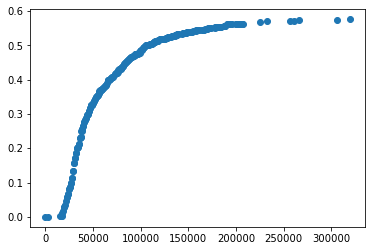

In [11]:
plt.scatter(ejection_df.columns,ejection_df.loc[0.01])

In [24]:


def find_t_stop(ejection_df, index):
    f = ejection_df.iloc[index].to_numpy()
    t = ejection_df.columns.to_numpy(dtype=float)

    peak_slope = -np.inf
    t_peak = None
    consecutive = 0

    for i in range(5, len(t)):
        # Update peak slope using a 5-point window
        slope = (f[i] - f[i-5]) / (t[i] - t[i-5])

        if slope > peak_slope:
            peak_slope = slope
            t_peak = t[i]

        # Look back 3*t_peak
        t_back = t[i] - 3*t_peak

        if f[i] < 0.07 or t_back < t[0]:
            continue

        j = np.searchsorted(t, t_back, side='right') - 1

        if f[i] - f[j] < 0.04:
            consecutive += 1
        else:
            consecutive = 0

        if consecutive >= 3:
            return t[i]

    return None



In [25]:
t_stop = find_t_stop(ejection_df, index=1)
print(t_stop)

260699.7438350171
